# #30DayMapChallenge - Day 4: Clusters
## Dual-Perspective Land-Cover Clusters: Graeme Hall Ramsar Sanctuary, Barbados

**Graeme Hall Swamp** is a significant coastal mangrove wetland and designated **Ramsar Site of International Importance** (Site #1591) in Barbados.

### Methodological Overview
1. **Cloud-Free Optical Composite:** Sentinel-2 Level-2A (harmonized surface reflectance) median composite for the dry season (Jan–May 2023) using QA60 cloud/cirrus bitmasking.
2. **Topographic Data:** Copernicus GLO-30 Digital Elevation Model (DEM) at 30m, resampled and aligned with Sentinel-2 10m grid.
3. **Multi-Spectral & Topographic Features: `[Elevation, NDVI, NDWI, NDMI]` (standardized)**
   - **Elevation** (Copernicus GLO-30 DEM): identifies tidal hydrologic gradients and upland terrestrial transitions.
   - **NDVI** (Normalized Difference Vegetation Index: `(B8 - B4) / (B8 + B4)`): separates photosynthetic canopy density from water and bare ground.
   - **NDWI** (Normalized Difference Water Index - McFeeters: `(B3 - B8) / (B3 + B8)`): delineates open brackish lagoons, channels, and saturated soils.
   - **NDMI** (Normalized Difference Moisture Index: `(B8 - B11) / (B8 + B11)`): differentiates waterlogged wetland mangrove roots/canopy from dry upland terrestrial grass, residential lawns, and agricultural fields.
4. **Unsupervised Clustering ($K$-Means, $K=5$):** Classifies the landscape into 5 distinct land-cover clusters:
   - Open Water (Lagoon / Sea)
   - Bare Ground / Built-up
   - Upland Grass & Lawns
   - Fringe Mangrove / Wet Vegetation (likely Rhizophora)
   - Dense Mangrove Canopy (likely Avicennia)
5. **Baseline Comparison & Change Monitoring:** Global Mangrove Watch (GMW v4.0.19) vector baseline (2020) is overlaid. According to GMW monitoring, the mangrove habitat extent in this sanctuary expanded by **+0.7 ha** between 2020 and 2025.

### 1. Cloud-Free Optical Composite & Multi-Spectral Feature Extraction (GEE)
Builds a cloud-masked Sentinel-2 L2A median composite for the 2023 dry season, computes spectral indices (NDVI, NDWI, NDMI), resamples Copernicus GLO-30 DEM to 10m, and pulls the aligned feature arrays directly into NumPy.

In [6]:
# Step 1: Cloud-Free Composite & Feature Extraction via GEE
import os
import warnings

# Prevent OpenMP runtime conflict warnings and set Matplotlib cache
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
warnings.filterwarnings("ignore", category=RuntimeWarning, module="threadpoolctl")
os.environ["MPLCONFIGDIR"] = os.path.join(os.environ.get("TEMP", "C:/Temp"), "matplotlib_cache")

import ee
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Initialize Google Earth Engine
# ee.Authenticate()  # Uncomment on first run if prompted to authenticate
EE_PROJECT_ID = "YOUR PROJECT ID"  # Replace with your GEE / Google Cloud Project ID if required

try:
    ee.Initialize(project=EE_PROJECT_ID)
except Exception:
    try:
        ee.Initialize()
    except Exception:
        ee.Authenticate()
        ee.Initialize()

# 1. Study AOI: Graeme Hall Swamp & Nature Sanctuary, Barbados
aoi = ee.Geometry.BBox(-59.5880, 13.0650, -59.5710, 13.0780)

# 2. Cloud mask function using S2 QA60 band
def mask_s2_clouds(image):
    qa = image.select("QA60")
    cloud_bit_mask = 1 << 10
    cirrus_bit_mask = 1 << 11
    mask = qa.bitwiseAnd(cloud_bit_mask).eq(0).And(
        qa.bitwiseAnd(cirrus_bit_mask).eq(0)
    )
    return image.updateMask(mask).divide(10000)

# 3. Build cloud-free Sentinel-2 L2A median composite (Dry season 2023)
s2_composite = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(aoi)
    .filterDate("2023-01-01", "2023-05-31")
    .map(mask_s2_clouds)
    .median()
    .clip(aoi)
)

# 4. Compute Spectral Indices
# NDVI: (NIR - RED) / (NIR + RED) -> (B8 - B4) / (B8 + B4)
ndvi = s2_composite.normalizedDifference(["B8", "B4"]).rename("ndvi")

# NDWI (McFeeters): (GREEN - NIR) / (GREEN + NIR) -> (B3 - B8) / (B3 + B8)
ndwi = s2_composite.normalizedDifference(["B3", "B8"]).rename("ndwi")

# NDMI (Moisture Index): (NIR - SWIR1) / (NIR + SWIR1) -> (B8 - B11) / (B8 + B11)
# Critical to differentiate saturated wetland mangroves from dry upland grass/lawns
ndmi = s2_composite.normalizedDifference(["B8", "B11"]).rename("ndmi")

# 5. Extract Elevation from Copernicus 30m Global DEM
dem = (
    ee.ImageCollection("COPERNICUS/DEM/GLO30_2024_1")
    .select("DEM")
    .mosaic()
    .rename("elevation")
    .clip(aoi)
)

# 6. Align and stack into a Multi-Band Feature Image: [Elevation, NDVI, NDWI, NDMI, RGB]
# Explicitly reproject to 10m WGS84 so all arrays share identical pixel grids
feature_stack = ee.Image.cat([
    dem.resample("bilinear"),
    ndvi,
    ndwi,
    ndmi,
    s2_composite.select(["B4", "B3", "B2"])
]).reproject(crs="EPSG:4326", scale=10)

# 7. Pull the processed array directly into Python at 10m scale
data_dict = feature_stack.sampleRectangle(region=aoi, defaultValue=0).getInfo()["properties"]

elev_arr = np.array(data_dict["elevation"], dtype=float)
ndvi_arr = np.array(data_dict["ndvi"], dtype=float)
ndwi_arr = np.array(data_dict["ndwi"], dtype=float)
ndmi_arr = np.array(data_dict["ndmi"], dtype=float)

# Extract True Colour bands (B4=Red, B3=Green, B2=Blue)
r_arr = np.array(data_dict["B4"], dtype=float)
g_arr = np.array(data_dict["B3"], dtype=float)
b_arr = np.array(data_dict["B2"], dtype=float)

# Stack into RGB array and apply 2-98% percentile stretch for crisp true-colour visualization
rgb = np.stack([r_arr, g_arr, b_arr], axis=-1)
p2, p98 = np.nanpercentile(rgb, (2, 98))
rgb_stretched = np.clip((rgb - p2) / (p98 - p2 + 1e-6), 0, 1)

print(f"Loaded feature raster grid of shape: {elev_arr.shape}")
print(f"Loaded Sentinel-2 RGB composite of shape: {rgb_stretched.shape}")


Loaded feature raster grid of shape: (146, 190)
Loaded Sentinel-2 RGB composite of shape: (146, 190, 3)


### 2. Unsupervised K-Means Clustering ($K=5$) & Cohesion Scoring
Standardizes features via `StandardScaler`, runs K-Means ($K=5$, `random_state=42`, `n_init=15`), maps cluster IDs to canonical land-cover names sorted by NDVI, and evaluates cluster cohesion using a 5,000-pixel sample Silhouette score.

In [7]:
# Step 2: Unsupervised K-Means Clustering (K=5: Isolating Upland Grass from Mangrove Fringe)
# Canonical display names for the 5 clusters defined once and reused everywhere
CLASS_NAMES = {
    0: "Open Water (Lagoon / Sea)",
    1: "Bare Ground / Built-up",
    2: "Upland Grass & Lawns",
    3: "Fringe Mangrove / Wet Vegetation (likely Rhizophora)",
    4: "Dense Mangrove Canopy (likely Avicennia)",
}

# Flatten grid for clustering with Elevation, NDVI, NDWI, and NDMI (Moisture)
valid_mask = ~np.isnan(ndvi_arr) & ~np.isnan(ndwi_arr) & ~np.isnan(ndmi_arr) & ~np.isnan(elev_arr)

X = np.column_stack([
    elev_arr[valid_mask],
    ndvi_arr[valid_mask],
    ndwi_arr[valid_mask],
    ndmi_arr[valid_mask]
])

# Standardize feature dimensions
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# K-Means with 5 clusters:
# 1. Open Water (Lagoon / Sea)
# 2. Bare Ground / Built-up
# 3. Upland Grass & Lawns
# 4. Fringe Mangrove / Wet Vegetation (likely Rhizophora)
# 5. Dense Mangrove Canopy (likely Avicennia)
N_CLUSTERS = 5
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=15)
labels = kmeans.fit_predict(X_scaled)

# Validation: Silhouette Score on a 5,000-pixel sample
from sklearn.metrics import silhouette_score
sil_score = float(silhouette_score(X_scaled, labels, sample_size=5000, random_state=42))

# Collect cluster signatures to determine ecological identity
stats = []
for i in range(N_CLUSTERS):
    m = labels == i
    stats.append({
        "Cluster": i,
        "Mean Elev (m)": float(np.mean(X[m, 0])),
        "Mean NDVI": float(np.mean(X[m, 1])),
        "Mean NDWI": float(np.mean(X[m, 2])),
        "Mean NDMI": float(np.mean(X[m, 3])),
        "Pixels": int(np.sum(m)),
        "Area (ha)": float(np.sum(m) * 0.01),  # 10m x 10m pixel = 100 m2 = 0.01 ha
    })

df_clusters = pd.DataFrame(stats).sort_values("Mean NDVI").reset_index(drop=True)
df_clusters["Class Name"] = [CLASS_NAMES[r] for r in df_clusters.index]
print("Ecological Cluster Profiles (sorted by NDVI):")
print(df_clusters[["Class Name", "Mean Elev (m)", "Mean NDVI", "Mean NDWI", "Mean NDMI", "Pixels", "Area (ha)"]].to_string(index=False))
print(f"\nSilhouette (k=5, 5,000-px sample): {sil_score:.2f}")

# Re-map cluster IDs in sorted order 0..4
sorted_cluster_ids = df_clusters["Cluster"].values
remap_dict = {orig: new_rank for new_rank, orig in enumerate(sorted_cluster_ids)}
remapped_labels = np.array([remap_dict[l] for l in labels])

# Re-project cluster labels onto the 2D spatial grid
cluster_grid = np.full(elev_arr.shape, np.nan)
cluster_grid[valid_mask] = remapped_labels


Ecological Cluster Profiles (sorted by NDVI):
                                          Class Name  Mean Elev (m)  Mean NDVI  Mean NDWI  Mean NDMI  Pixels  Area (ha)
                           Open Water (Lagoon / Sea)            0.0  -0.046555   0.205494   0.049667   10014     100.14
                              Bare Ground / Built-up            0.0   0.149987  -0.167569  -0.023449    5253      52.53
                                Upland Grass & Lawns            0.0   0.304758  -0.322354   0.042146    6378      63.78
Fringe Mangrove / Wet Vegetation (likely Rhizophora)            0.0   0.430034  -0.417067   0.146559    3739      37.39
            Dense Mangrove Canopy (likely Avicennia)            0.0   0.568481  -0.513329   0.309757    2356      23.56

Silhouette (k=5, 5,000-px sample): 0.42


### 3. Global Mangrove Watch (GMW v4.0.19) Baseline Vector Extraction
Fetches the official GMW 2020 mangrove extent polygon from the Awesome-GEE-Community-Catalog to benchmark the unsupervised classification against an independent radar/optical product.

In [8]:
# Fetch Global Mangrove Watch (GMW v4.0.19) Vector Baseline from GEE Community Catalog
gmw_vec_2020 = ee.FeatureCollection(
    "projects/sat-io/open-datasets/GMW/annual-extent/GMW_MNG_VEC_2020"
).filterBounds(aoi)

gmw_data = gmw_vec_2020.getInfo()
gdf_gmw = gpd.GeoDataFrame.from_features(gmw_data["features"], crs="EPSG:4326")
print(f"Loaded {len(gdf_gmw)} GMW v4.0.19 mangrove baseline polygon(s).")


Loaded 1 GMW v4.0.19 mangrove baseline polygon(s).


### 4. Dual-Perspective Production Map: Clusters vs Sentinel-2 True Colour
Renders the final cartographic split-screen visualization: the upper half depicts the unsupervised K-Means clusters, while the lower half displays the Sentinel-2 true-colour composite (B4, B3, B2) with the GMW boundary overlay and a lower-left metrics card.

Dense Canopy vs GMW 2020 diff: +22.9% (23.6 vs 19.2 ha)
Map successfully exported to: graeme_hall_mangrove_clusters_split.png


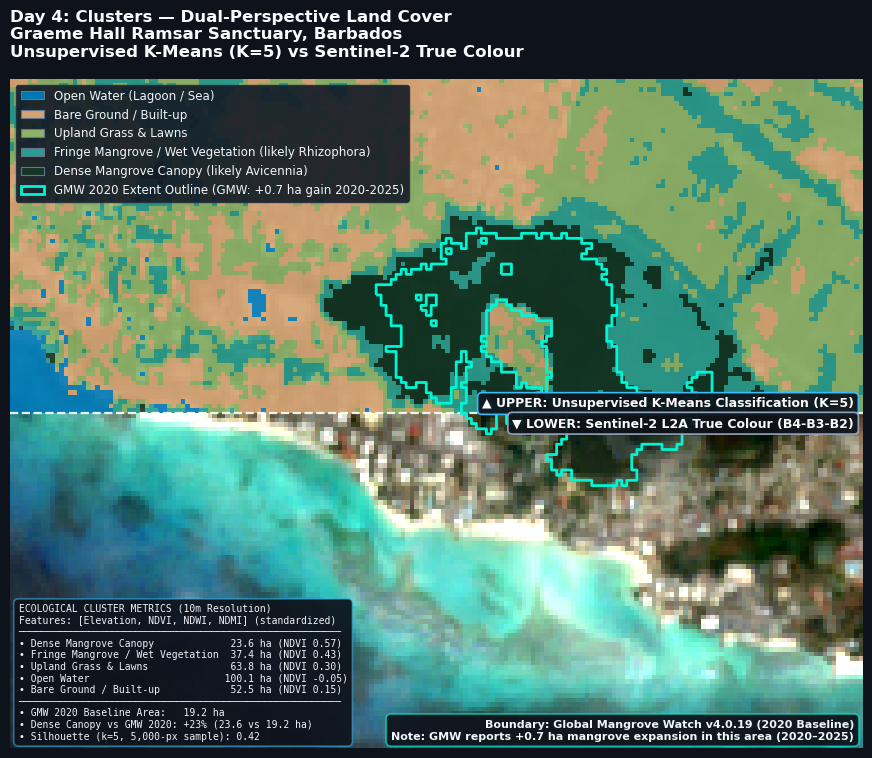

In [9]:
# Step 3: High-Impact Cartographic Visualization (Day 4: Clusters - Split Comparison)
# Assumes earlier cells defined: gpd, np, plt, cluster_grid, rgb_stretched, gdf_gmw,
# df_clusters, CLASS_NAMES, sil_score
import contextily as cx
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches

# Bounding coordinates in WGS84
minx, miny, maxx, maxy = -59.5880, 13.0650, -59.5710, 13.0780

# Convert bounding box to Web Mercator for tile alignment
gdf_aoi = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy([minx, maxx], [miny, maxy]), crs=4326
).to_crs(epsg=3857)
extent_3857 = [
    gdf_aoi.geometry.x.min(),
    gdf_aoi.geometry.x.max(),
    gdf_aoi.geometry.y.min(),
    gdf_aoi.geometry.y.max(),
]

# 1. Prepare Split Display (Upper Half: Clusters, Lower Half: True Colour)
h, w = cluster_grid.shape
split_row = h // 2
upper_clusters = cluster_grid.copy()
upper_clusters[split_row:, :] = np.nan  # Mask lower half

# Projected split coordinate for horizontal divider
split_y = extent_3857[3] - (split_row / h) * (extent_3857[3] - extent_3857[2])

# Colour map ordered by the 5 zones (sorted by NDVI / moisture):
# 0 Open Water, 1 Bare Ground / Built-up, 2 Upland Grass, 3 Fringe Mangrove, 4 Dense Canopy
zone_colors = ["#0077b6", "#d4a373", "#8cb369", "#2a9d8f", "#143625"]
cmap_custom = ListedColormap(zone_colors)

fig, ax = plt.subplots(figsize=(11, 10), facecolor="#0e131b")
ax.set_facecolor("#0e131b")

# Sentinel-2 true colour (visible across lower half)
ax.imshow(rgb_stretched, extent=extent_3857, origin="upper", zorder=2)

# Clusters (upper half only)
ax.imshow(
    upper_clusters,
    extent=extent_3857,
    origin="upper",
    cmap=cmap_custom,
    alpha=0.92,
    zorder=3,
)

# Divider line
ax.axhline(split_y, color="#ffffff", linestyle="--", linewidth=1.6, alpha=0.9, zorder=4)

# GMW v4.0.19 2020 baseline outline
gdf_gmw_3857 = gdf_gmw.to_crs(epsg=3857)
gdf_gmw_3857.boundary.plot(ax=ax, color="#00f5d4", linewidth=2.0, linestyle="-", zorder=5)

# Perspective badges (offsets are in axes fractions so spacing is identical in notebook and PNG)
ax.text(
    0.99, (split_y - extent_3857[2]) / (extent_3857[3] - extent_3857[2]) + 0.005,
    "▲ UPPER: Unsupervised K-Means Classification (K=5)",
    transform=ax.transAxes,
    color="#f8fafc", fontsize=9, fontweight="bold", ha="right", va="bottom",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#0e131bee", edgecolor="#38bdf8", linewidth=1.2),
    zorder=6,
)
ax.text(
    0.99, (split_y - extent_3857[2]) / (extent_3857[3] - extent_3857[2]) - 0.005,
    "▼ LOWER: Sentinel-2 L2A True Colour (B4-B3-B2)",
    transform=ax.transAxes,
    color="#f8fafc", fontsize=9, fontweight="bold", ha="right", va="top",
    bbox=dict(boxstyle="round,pad=0.35", facecolor="#0e131bee", edgecolor="#94a3b8", linewidth=1.2),
    zorder=6,
)

# Lower-right GMW note
ax.text(
    0.99, 0.01,
    "Boundary: Global Mangrove Watch v4.0.19 (2020 Baseline)\n"
    "Note: GMW reports +0.7 ha mangrove expansion in this area (2020–2025)",
    transform=ax.transAxes,
    color="#f1f5f9", fontsize=8, fontweight="semibold", ha="right", va="bottom",
    bbox=dict(boxstyle="round,pad=0.45", facecolor="#0e131bee", edgecolor="#00f5d4aa", linewidth=1.2),
    zorder=6,
)

# Lower-left stats card
dense_area_ha = float(df_clusters.loc[4, "Area (ha)"])
gmw_area_ha = float(gdf_gmw_3857.area.sum() / 10000.0)
pct_diff = (dense_area_ha - gmw_area_ha) / gmw_area_ha * 100
print(f"Dense Canopy vs GMW 2020 diff: {pct_diff:+.1f}% ({dense_area_ha:.1f} vs {gmw_area_ha:.1f} ha)")

short = lambda i: CLASS_NAMES[i].split(" (")[0]  # drop parenthetical; full name stays in legend
rows = "\n".join(
    f"• {short(i):<32} {df_clusters.loc[i, 'Area (ha)']:5.1f} ha (NDVI {df_clusters.loc[i, 'Mean NDVI']:.2f})"
    for i in (4, 3, 2, 0, 1)
)
sep = "─" * 55
stats_card = (
    "ECOLOGICAL CLUSTER METRICS (10m Resolution)\n"
    "Features: [Elevation, NDVI, NDWI, NDMI] (standardized)\n"
    f"{sep}\n{rows}\n{sep}\n"
    f"• GMW 2020 Baseline Area:  {gmw_area_ha:5.1f} ha\n"
    f"• Dense Canopy vs GMW 2020: {pct_diff:+.0f}% ({dense_area_ha:.1f} vs {gmw_area_ha:.1f} ha)\n"
    f"• Silhouette (k=5, 5,000-px sample): {sil_score:.2f}"
)
ax.text(
    0.01, 0.01,
    stats_card,
    transform=ax.transAxes,
    color="#f1f5f9", fontsize=7, fontfamily="monospace", ha="left", va="bottom",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#0e131bee", edgecolor="#38bdf888", linewidth=1.2),
    zorder=6,
)

# Upper-left legend
legend_items = [
    mpatches.Patch(facecolor=zone_colors[i], edgecolor="#64748b", linewidth=0.8, label=CLASS_NAMES[i])
    for i in range(5)
]
legend_items.append(
    mpatches.Patch(
        facecolor="none", edgecolor="#00f5d4", linewidth=2.0,
        label="GMW 2020 Extent Outline (GMW: +0.7 ha gain 2020-2025)",
    )
)
leg = ax.legend(
    handles=legend_items, loc="upper left", framealpha=0.92,
    facecolor="#161d27", edgecolor="#243040", fontsize=8.5, labelcolor="#f1f5f9",
)
leg.set_zorder(6)

ax.set_xlim(extent_3857[0], extent_3857[1])
ax.set_ylim(extent_3857[2], extent_3857[3])
ax.set_axis_off()

# Three shorter title lines so the title no longer widens the saved image
ax.set_title(
    "Day 4: Clusters — Dual-Perspective Land Cover\n"
    "Graeme Hall Ramsar Sanctuary, Barbados\n"
    "Unsupervised K-Means (K=5) vs Sentinel-2 True Colour",
    fontsize=12, fontweight="bold", color="#f8fafc", pad=16, loc="left",
)

output_map = "graeme_hall_mangrove_clusters_split.png"
plt.savefig(output_map, dpi=300, bbox_inches="tight", facecolor="#0e131b")
print(f"Map successfully exported to: {output_map}")
plt.show()

### 5. Cluster Cohesion & Silhouette Analysis Breakdown
Performs an in-depth breakdown of the Silhouette metric across binned ranges (`<0` to `>0.8`) and per-class average cohesion scores to inspect cluster separation at pixel level.

In [10]:
from sklearn.metrics import silhouette_samples
import numpy as np
import pandas as pd

# 1. Sample 5,000 pixels for fast, representative analysis
np.random.seed(42)
sample_idx = np.random.choice(
    len(X_scaled), size=min(5000, len(X_scaled)), replace=False
)
X_sub = X_scaled[sample_idx]
labels_sub = labels[sample_idx]

# Calculate individual silhouette score for each sampled pixel
sample_sil = silhouette_samples(X_sub, labels_sub)

# 2. Binned Classbreak Distribution
bins = [-1.0, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]
bin_labels = [
    "< 0.0 (Transition / Ecotone)",
    "0.0 - 0.1",
    "0.1 - 0.2",
    "0.2 - 0.3",
    "0.3 - 0.4",
    "0.4 - 0.5",
    "0.5 - 0.6",
    "0.6 - 0.7",
    "0.7 - 0.8",
    "> 0.8 (Strong Core)",
]

counts, _ = np.histogram(sample_sil, bins=bins)
pcts = counts / len(sample_sil) * 100

df_binned = pd.DataFrame(
    {
        "Silhouette Classbreak": bin_labels,
        "Pixels": counts,
        "Share (%)": [f"{p:5.1f}%" for p in pcts],
        "Visual Distribution": [
            "█" * int(p // 2) if p >= 2 else "▏" if p > 0 else "" for p in pcts
        ],
    }
)

print("=== SILHOUETTE CLASSBREAK DISTRIBUTION ===")
print(df_binned.to_string(index=False))

# 3. Per-Class Silhouette Breakdown (using canonical CLASS_NAMES constant)
class_scores = []
for orig_id, new_rank in remap_dict.items():
    m = labels_sub == orig_id
    class_scores.append(
        {
            "Rank": new_rank,
            "Ecological Class": CLASS_NAMES[new_rank],
            "Mean Silhouette": float(np.mean(sample_sil[m]))
            if np.sum(m) > 0
            else np.nan,
            "Sampled Pixels": int(np.sum(m)),
        }
    )

df_per_class = (
    pd.DataFrame(class_scores).sort_values("Rank").reset_index(drop=True)
)
print("\n=== PER-CLASS SILHOUETTE COHESION ===")
print(df_per_class.to_string(index=False))


=== SILHOUETTE CLASSBREAK DISTRIBUTION ===
       Silhouette Classbreak  Pixels Share (%) Visual Distribution
< 0.0 (Transition / Ecotone)      30      0.6%                   ▏
                   0.0 - 0.1     354      7.1%                 ███
                   0.1 - 0.2     392      7.8%                 ███
                   0.2 - 0.3     498     10.0%                ████
                   0.3 - 0.4     674     13.5%              ██████
                   0.4 - 0.5     842     16.8%            ████████
                   0.5 - 0.6    1497     29.9%      ██████████████
                   0.6 - 0.7     713     14.3%             ███████
                   0.7 - 0.8       0      0.0%                    
         > 0.8 (Strong Core)       0      0.0%                    

=== PER-CLASS SILHOUETTE COHESION ===
 Rank                                     Ecological Class  Mean Silhouette  Sampled Pixels
    0                            Open Water (Lagoon / Sea)         0.487229            18